# ML07: Combine precursors with persistence (final baseline)
**Why:** ML04-05 showed two different strengths. Persistence (yesterday's rain) catches the strongest days because extreme days come in spells.
Atmospheric precursors rise **before** a spell starts. A combined model should beat both.

**This notebook**
1. Adds rain on the previous 1-3 days (log-scaled) to the 41 atmospheric features.
2. Compares persistence, precursors, and the combined model with the same 5-block year-wise cross-validation.
3. Scores **spell onsets** separately (extreme days whose previous day was not extreme): this is where early warning matters.
4. Explains the combined XGBoost model with SHAP and writes `results/summary_final.txt`.

In [1]:
!pip install -q shap

In [2]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

Mounted at /content/drive


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

table = pd.read_csv(f'{DATA}/features_{TARGET}.csv', index_col=0, parse_dates=True)
y, yr = table['extreme'], table.index.year
ATMOS = [c_ for c_ in table if '_lag' in c_ and c_ != 'rain_lag1'] + ['doy_sin', 'doy_cos']
LAG1  = [c_ for c_ in ATMOS if c_.endswith('_lag1')] + ['doy_sin', 'doy_cos']
train = yr <= 2024
BLOCKS = np.array_split(TRAIN_YEARS, 5)        # 5 blocks of ~9 consecutive years: train on 4, test on 1
print(len(ATMOS), 'atmospheric features |', int(y[train].sum()), 'extreme days in', int(train.sum()), 'training days')

def cv_predict(make_model, cols):
    """Out-of-fold probabilities for 1979-2024: each block is predicted by a model that never saw those years."""
    p = pd.Series(np.nan, index=table.index[train])
    for blk in BLOCKS:
        te = np.isin(yr[train], blk); tr_ = ~te
        if te.sum() == 0: continue                 # block with no data yet (years still downloading)
        m = make_model().fit(table.loc[train, cols][tr_], y[train][tr_])
        p[te] = m.predict_proba(table.loc[train, cols][te])[:, 1]
    return p

def scores(p, name):
    yt = y[train]; base = yt.mean()
    k = max(1, int(round(0.05 * len(p))))                    # the 5% of days with the highest probability
    top = p.sort_values(ascending=False).index[:k]
    return dict(model=name,
                ROC_AUC=round(roc_auc_score(yt, p), 3),
                PR_AUC=round(average_precision_score(yt, p), 3), base_rate=round(base, 3),
                BSS=round(1 - brier_score_loss(yt, p) / brier_score_loss(yt, np.full(len(p), base)), 3),
                hit_rate_top5pct=round(yt.loc[top].mean(), 3),
                extremes_caught_top5pct=round(yt.loc[top].sum() / yt.sum(), 3))

def logreg(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))

def plot_2025(models, fname, title):
    """Fit each model on 1979-2024 and plot its 2025 probabilities with the IMD rain."""
    t25 = table[(yr == 2025)].loc['2025-07-15':'2025-09-20']
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    ax2 = ax.twinx()
    ax2.bar(t25.index, t25['rain'], color='grey', alpha=.35, width=.8, label='IMD rain (right axis)')
    ax2.set_ylabel('IMD basin rain (mm/day)')
    for name, (make, cols) in models.items():
        m = make().fit(table.loc[train, cols], y[train])
        ax.plot(t25.index, m.predict_proba(t25[cols])[:, 1], '-o', ms=3, lw=1.8, label=name)
    for k, (a, b) in EPISODES.items():
        ax.axvspan(pd.Timestamp(a) - pd.Timedelta('12h'), pd.Timestamp(b) + pd.Timedelta('12h'), color='orange', alpha=.15)
        ax.text(pd.Timestamp(a), 0.97, k, transform=ax.get_xaxis_transform(), fontweight='bold')
    ax.axhline(y[train].mean(), color='k', ls=':', lw=1, label='climatology')
    ax.set_ylim(0, 1); ax.set_ylabel('P(extreme day)'); ax.set_title(title)
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.legend(loc='upper left', fontsize=8)
    plt.savefig(f'{RES}/{fname}', dpi=150); plt.show()

41 atmospheric features | 281 extreme days in 5566 training days


In [4]:
from xgboost import XGBClassifier
lab = pd.read_csv(f'{DATA}/labels_{TARGET}_p{PCT}.csv', index_col=0, parse_dates=True)
for L in (1, 2, 3):
    table[f'lograin_lag{L}'] = np.log1p(lab['rain'].shift(L, freq='D').reindex(table.index))
table = table.dropna()
y, yr = table['extreme'], table.index.year
train = yr <= 2024
PERS = ['lograin_lag1', 'lograin_lag2', 'lograin_lag3']
BOTH = ATMOS + PERS
def xgb(): return XGBClassifier(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7,
                                min_child_weight=5, reg_lambda=2.0, eval_metric='logloss', n_jobs=-1, random_state=0)
MODELS = {'Persistence (rain 1-3 days before)': (logreg, PERS),
          'Precursors only (LogReg)': (logreg, ATMOS),
          'Combined (LogReg)': (logreg, BOTH),
          'Combined (XGBoost)': (xgb, BOTH)}
oof = {k: cv_predict(f, cols) for k, (f, cols) in MODELS.items()}
res = pd.DataFrame([scores(p, k) for k, p in oof.items()]).set_index('model')
res.to_csv(f'{RES}/ml07_scores.csv'); pd.DataFrame(oof).to_csv(f'{RES}/ml07_oof_probs.csv')
print(table.shape[0], 'days |', int(y[train].sum()), 'extreme days in training')
print(res.to_string())

5593 days | 281 extreme days in training
                                    ROC_AUC  PR_AUC  base_rate    BSS  hit_rate_top5pct  extremes_caught_top5pct
model                                                                                                           
Persistence (rain 1-3 days before)    0.788   0.219      0.051  0.088             0.285                    0.278
Precursors only (LogReg)              0.806   0.196      0.051  0.069             0.223                    0.217
Combined (LogReg)                     0.833   0.237      0.051  0.093             0.277                    0.270
Combined (XGBoost)                    0.832   0.251      0.051  0.110             0.310                    0.302


**How to read the scores**
- **ROC AUC**: 0.5 = no skill (coin toss), 1 = perfect ranking of extreme vs normal days.
- **PR AUC**: compare with the base rate (about 0.05). Twice the base rate already means useful skill for rare events.
- **BSS** (Brier skill score): above 0 = better probabilities than always forecasting the climatological 5%.
- **hit_rate_top5pct**: of the 5% of days with the highest forecast probability, how many really were extreme.
- **extremes_caught_top5pct**: which share of all extreme days fall in that top 5%.

## Spell onsets: can the models warn before a spell starts?
An **onset** is an extreme day whose previous day was not extreme. Persistence cannot see these coming; precursors can.
The table shows, for each model, the share of onset days that fall in its top 5% highest-probability days, and the ROC AUC on onset days versus non-extreme days.

In [5]:
ytr = y[train]
prev = lab['extreme'].shift(1, freq='D').reindex(ytr.index).fillna(0)
onset = (ytr == 1) & (prev == 0)
cont = (ytr == 1) & (prev == 1)
rows = []
for k, p in oof.items():
    thr = p.quantile(0.95)
    keep = onset | (ytr == 0)
    rows.append(dict(model=k, onsets=int(onset.sum()), continuations=int(cont.sum()),
                     onsets_in_top5pct=round((p[onset] >= thr).mean(), 3),
                     continuations_in_top5pct=round((p[cont] >= thr).mean(), 3),
                     onset_ROC_AUC=round(roc_auc_score(onset[keep].astype(int), p[keep]), 3)))
ons = pd.DataFrame(rows).set_index('model'); ons.to_csv(f'{RES}/ml07_onsets.csv')
print(ons.to_string())

                                    onsets  continuations  onsets_in_top5pct  continuations_in_top5pct  onset_ROC_AUC
model                                                                                                                
Persistence (rain 1-3 days before)     202             79              0.015                     0.949          0.712
Precursors only (LogReg)               202             79              0.119                     0.468          0.772
Combined (LogReg)                      202             79              0.124                     0.646          0.784
Combined (XGBoost)                     202             79              0.129                     0.747          0.780


## 2025 test (models trained on 1979-2024)

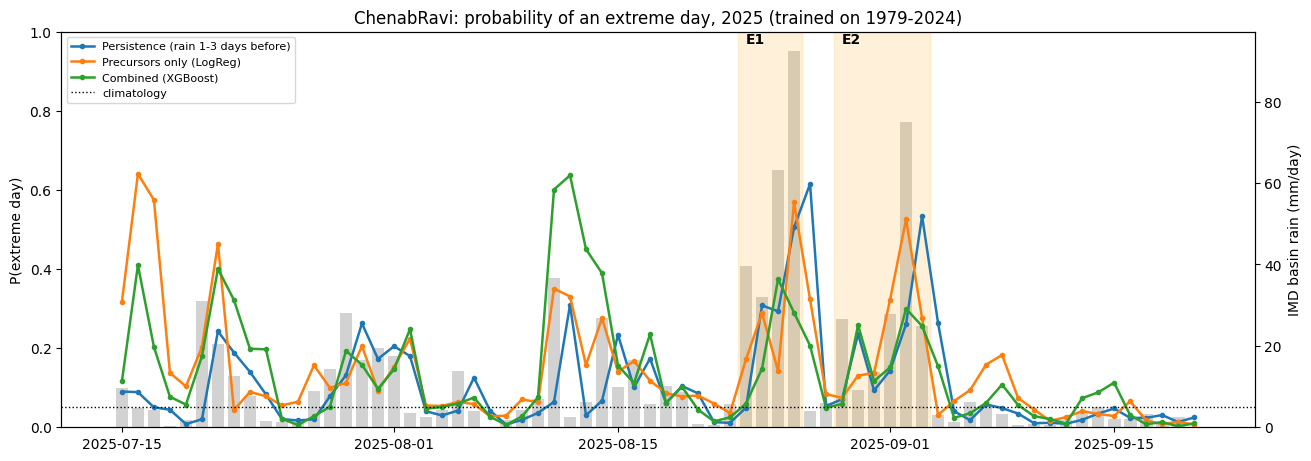

In [6]:
plot_2025({k: MODELS[k] for k in ['Persistence (rain 1-3 days before)', 'Precursors only (LogReg)', 'Combined (XGBoost)']},
          'ml07_forecast_2025.png', f'{TARGET}: probability of an extreme day, 2025 (trained on 1979-2024)')

## SHAP for the combined XGBoost model

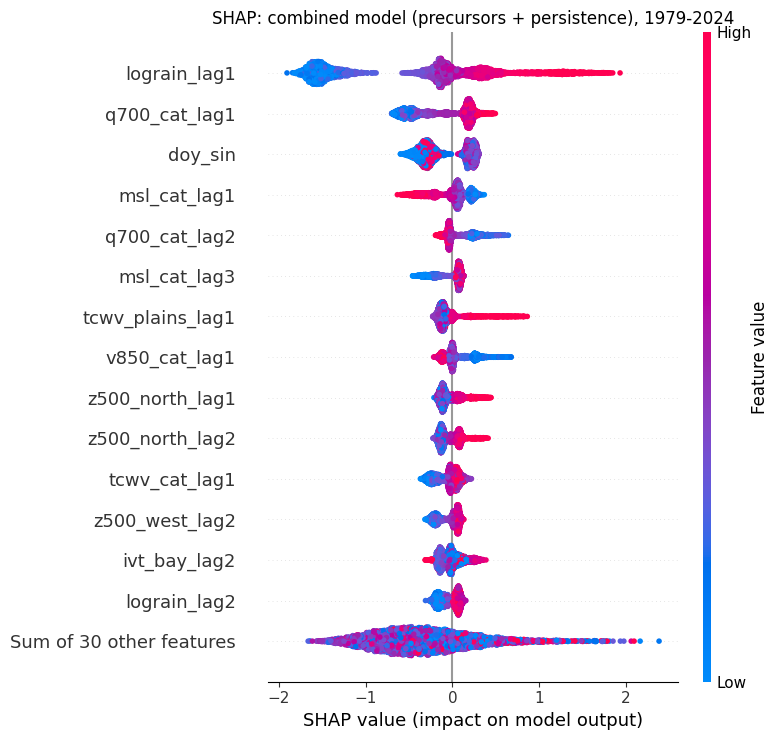

atmospheric precursors      0.70
persistence (rain 1-3 d)    0.23
season                      0.08


In [7]:
import shap
model = xgb().fit(table.loc[train, BOTH], y[train])
sv = shap.TreeExplainer(model)(table.loc[train, BOTH])
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP: combined model (precursors + persistence), 1979-2024'); plt.tight_layout()
plt.savefig(f'{RES}/ml07_shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=BOTH)
grp = imp.groupby(lambda c_: 'persistence (rain 1-3 d)' if c_.startswith('lograin') else
                  ('season' if c_.startswith('doy') else 'atmospheric precursors')).sum()
print((grp / grp.sum()).round(2).to_string())

## Summary for emails and GitHub (results/summary_final.txt)

In [8]:
t25 = table[yr == 2025]
m25 = xgb().fit(table.loc[train, BOTH], y[train])
p25 = pd.Series(m25.predict_proba(t25[BOTH])[:, 1], index=t25.index)
lines = [f'Target: extreme rain days (>= {PCT}th percentile of JJAS days) over the {TARGET} catchments, IMD 0.25 deg, 1979-2025.',
         'Validation: 5-block year-wise cross-validation on 1979-2024; 2025 held out.']
for mname, r in res.iterrows():
    lines.append(f'{mname}: ROC AUC {r.ROC_AUC}, PR AUC {r.PR_AUC} (base rate {r.base_rate}), BSS {r.BSS}, top-5% hit rate {r.hit_rate_top5pct}')
for mname, r in ons.iterrows():
    lines.append(f'Onsets, {mname}: {r.onsets_in_top5pct:.0%} of {r.onsets} spell-onset days in top 5%; onset ROC AUC {r.onset_ROC_AUC}')
lines.append('SHAP share (combined XGBoost): ' + ', '.join(f'{k} {v:.0%}' for k, v in (grp / grp.sum()).items()))
for k, (a, b) in EPISODES.items():
    d = t25.loc[a:b, 'rain'].idxmax()
    lines.append(f'2025 {k} peak day {d:%d %b}: combined probability {p25[d]:.2f} (climatology {y[train].mean():.2f})')
txt = '\n'.join(lines); print(txt); open(f'{RES}/summary_final.txt', 'w').write(txt + '\n')

Target: extreme rain days (>= 95th percentile of JJAS days) over the ChenabRavi catchments, IMD 0.25 deg, 1979-2025.
Validation: 5-block year-wise cross-validation on 1979-2024; 2025 held out.
Persistence (rain 1-3 days before): ROC AUC 0.788, PR AUC 0.219 (base rate 0.051), BSS 0.088, top-5% hit rate 0.285
Precursors only (LogReg): ROC AUC 0.806, PR AUC 0.196 (base rate 0.051), BSS 0.069, top-5% hit rate 0.223
Combined (LogReg): ROC AUC 0.833, PR AUC 0.237 (base rate 0.051), BSS 0.093, top-5% hit rate 0.277
Combined (XGBoost): ROC AUC 0.832, PR AUC 0.251 (base rate 0.051), BSS 0.11, top-5% hit rate 0.31
Onsets, Persistence (rain 1-3 days before): 2% of 202.0 spell-onset days in top 5%; onset ROC AUC 0.712
Onsets, Precursors only (LogReg): 12% of 202.0 spell-onset days in top 5%; onset ROC AUC 0.772
Onsets, Combined (LogReg): 12% of 202.0 spell-onset days in top 5%; onset ROC AUC 0.784
Onsets, Combined (XGBoost): 13% of 202.0 spell-onset days in top 5%; onset ROC AUC 0.78
SHAP share (c

1226

## Think about it
1. Does the combined model beat both persistence and precursors? On which score?
2. Look at the onset table: which model warns best **before** a spell starts? That is the precursor story for your applications.
3. How much of the SHAP importance goes to persistence versus atmospheric precursors?